In [1]:
# ===== Imports and data loading =====
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
print("Shape:", df.shape)
print(df.head())

Shape: (395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [2]:
# ===== Three class risk label derived from G3 =====
def assign_risk(g3):
    if g3 <= 9:
        return "High"
    elif g3 <= 13:
        return "Medium"
    return "Low"

df["risk"] = df["G3"].apply(assign_risk)

risk_order = ["High", "Medium", "Low"]
counts = df["risk"].value_counts().reindex(risk_order)

print(counts)
print((counts / len(df)).round(3))
print("\nStudents with a final grade of exactly zero:", (df["G3"] == 0).sum())

risk
High      130
Medium    165
Low       100
Name: count, dtype: int64
risk
High      0.329
Medium    0.418
Low       0.253
Name: count, dtype: float64

Students with a final grade of exactly zero: 38


In [3]:
# ===== Inspect the zero grade students =====
zeros = df[df["G3"] == 0]

print("Zero G3 students:", len(zeros))
print("Of these, G2 equals 0:", (zeros["G2"] == 0).sum())
print("Of these, G1 equals 0:", (zeros["G1"] == 0).sum())

print("\nG2 summary for zero G3 students")
print(zeros["G2"].describe().round(2))
print("\nAbsences for zero G3 vs the rest")
print(zeros["absences"].mean().round(2), df[df["G3"] > 0]["absences"].mean().round(2))

Zero G3 students: 38
Of these, G2 equals 0: 13
Of these, G1 equals 0: 0

G2 summary for zero G3 students
count    38.00
mean      4.66
std       3.70
min       0.00
25%       0.00
50%       5.00
75%       8.00
max      10.00
Name: G2, dtype: float64

Absences for zero G3 vs the rest
0.0 6.32


In [5]:
# ===== Structure and quality checks =====
df.info()

print("\nMissing values per column")
print(df.isnull().sum().sum(), "missing values in total")

print("\nDuplicate rows")
print(df.duplicated().sum())

print("\nNumeric summary")
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


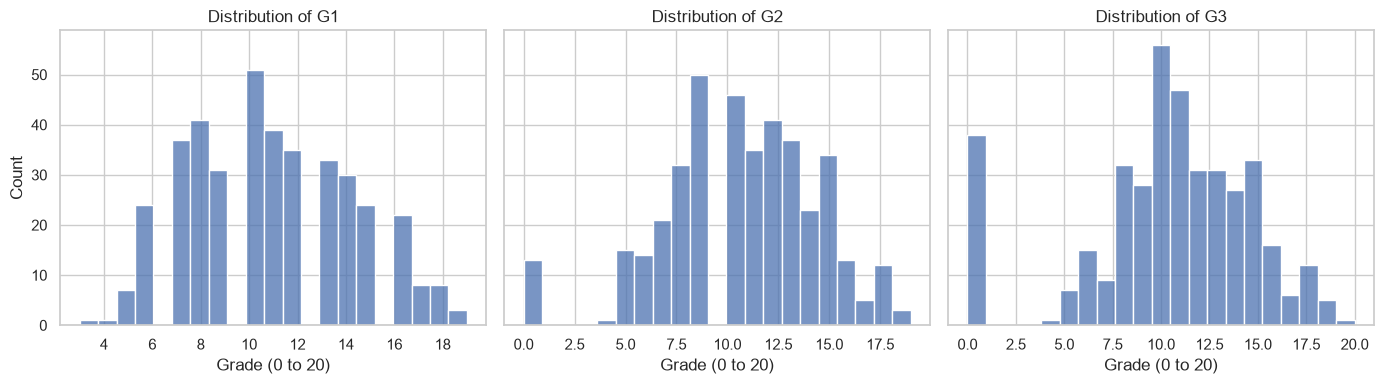

In [6]:
# ===== Grade distributions =====
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, col in zip(axes, ["G1", "G2", "G3"]):
    sns.histplot(df[col], bins=21, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Grade (0 to 20)")

plt.tight_layout()
plt.savefig("../outputs/figures/grade_distributions.png", dpi=200)
plt.show()

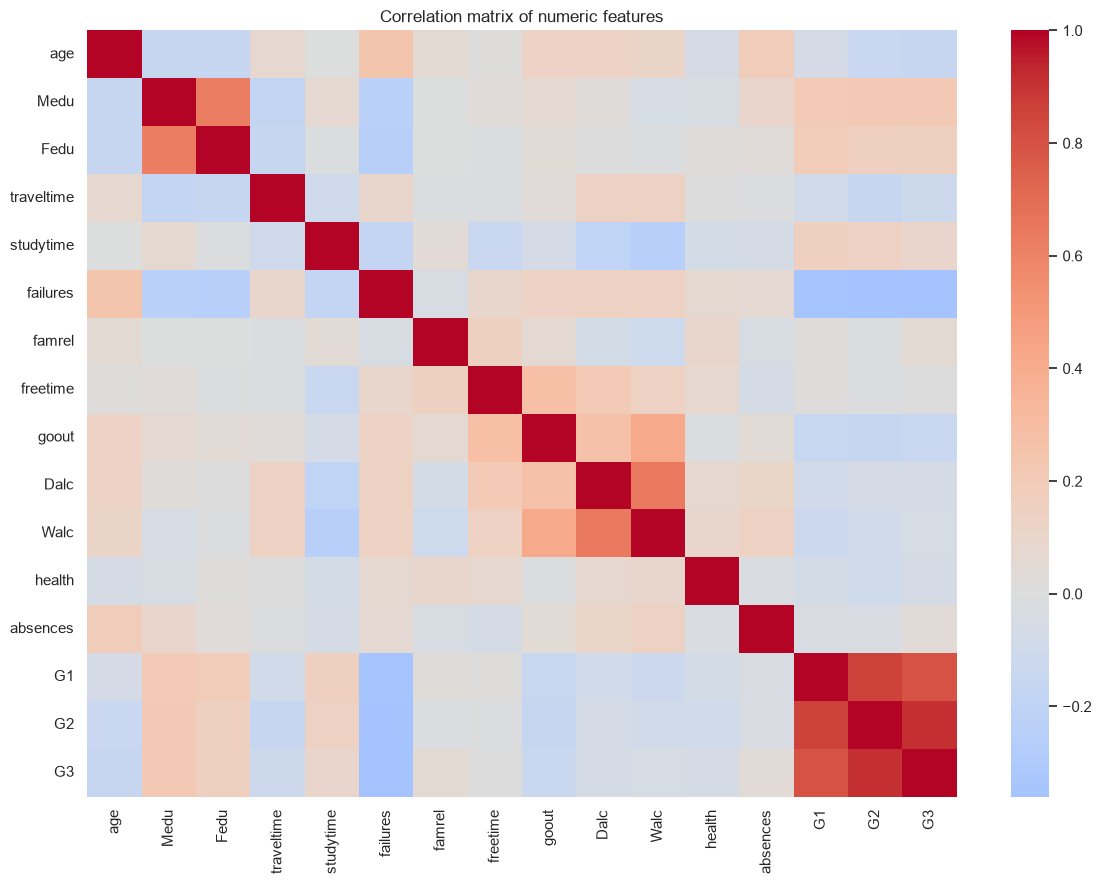

G3            1.00
G2            0.90
G1            0.80
Medu          0.22
Fedu          0.15
studytime     0.10
famrel        0.05
absences      0.03
freetime      0.01
Walc         -0.05
Dalc         -0.05
health       -0.06
traveltime   -0.12
goout        -0.13
age          -0.16
failures     -0.36
Name: G3, dtype: float64


In [7]:
# ===== Correlation analysis =====
numeric_cols = df.select_dtypes(include="number")
corr = numeric_cols.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix of numeric features")
plt.tight_layout()
plt.savefig("../outputs/figures/correlation_heatmap.png", dpi=200)
plt.show()

print(corr["G3"].sort_values(ascending=False).round(2))